# Notebook 3: Sampling Strategies

## Choosing the Next Token from a Probability Distribution

The model gives us probabilities over 50,000+ tokens. Now we need to **pick one**. The choice of sampling strategy dramatically affects the output quality and diversity.

We'll implement each strategy from scratch, then compare them side by side.

In [1]:
import torch
import torch.nn.functional as F
from transformers import GPT2LMHeadModel, GPT2Tokenizer
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")

tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2")
model.eval()

def get_next_token_probs(prompt):
    """Get the full probability distribution for the next token."""
    input_ids = tokenizer.encode(prompt, return_tensors="pt")
    with torch.no_grad():
        logits = model(input_ids).logits[0, -1, :]
    return logits, F.softmax(logits, dim=0)

/Users/nijjohnson/Projects/token-probabilities/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 23641.58it/s]


## Strategy 1: Greedy Decoding (argmax)

**Always pick the token with the highest probability.** Deterministic — same input always gives the same output.

- **Pro:** Fast, consistent, good for factual tasks
- **Con:** Repetitive, boring, can get stuck in loops

In [2]:
def greedy_decode(logits):
    """Pick the single most probable token."""
    return logits.argmax(dim=0)

prompt = "The future of artificial intelligence"
logits, probs = get_next_token_probs(prompt)

# Show the greedy choice
greedy_idx = greedy_decode(logits)
print(f'Prompt: "{prompt}"')
print(f'Greedy pick: "{tokenizer.decode([greedy_idx])}" (prob: {probs[greedy_idx]:.1%})')

# Show what we're missing by always picking the top
top_probs, top_indices = torch.topk(probs, 10)
print(f"\nFull top-10 distribution:")
for rank, (p, idx) in enumerate(zip(top_probs, top_indices), 1):
    marker = " ← GREEDY" if idx == greedy_idx else ""
    print(f"  {rank:2d}. {tokenizer.decode([idx]):>12s}  {p:6.1%}{marker}")

Prompt: "The future of artificial intelligence"
Greedy pick: " is" (prob: 28.9%)

Full top-10 distribution:
   1.           is   28.9% ← GREEDY
   2.            ,    6.4%
   3.          and    6.3%
   4.         will    5.9%
   5.           in    5.0%
   6.            
    3.3%
   7.          may    3.0%
   8.          has    2.9%
   9.            .    2.1%
  10.            :    2.0%


## Strategy 2: Pure Random Sampling

**Sample from the full distribution** — every token has a chance proportional to its probability.

- **Pro:** Maximum diversity
- **Con:** Can pick garbage tokens from the long tail (e.g., random punctuation, nonsense)

In [3]:
def random_sample(probs, n_samples=1):
    """Sample from the full probability distribution."""
    return torch.multinomial(probs, n_samples, replacement=True)

# Sample 20 times to show the variance
print(f'Prompt: "{prompt}" → ___\n')
print("20 random samples from the full distribution:")
torch.manual_seed(42)
samples = random_sample(probs, 20)
for i, idx in enumerate(samples):
    token = tokenizer.decode([idx]).replace("\n", "\\n")
    print(f"  Sample {i+1:2d}: {token:>15s}  (prob: {probs[idx]:.4%})")

# How many unique tokens?
unique = len(set(samples.tolist()))
print(f"\n{unique} unique tokens out of 20 samples")

Prompt: "The future of artificial intelligence" → ___

20 random samples from the full distribution:
  Sample  1:               ,  (prob: 6.3970%)
  Sample  2:               ,  (prob: 6.3970%)
  Sample  3:              \n  (prob: 3.2786%)
  Sample  4:               ,  (prob: 6.3970%)
  Sample  5:              is  (prob: 28.9088%)
  Sample  6:              is  (prob: 28.9088%)
  Sample  7:         depends  (prob: 0.8772%)
  Sample  8:          models  (prob: 0.0288%)
  Sample  9:               .  (prob: 2.0654%)
  Sample 10:              \n  (prob: 3.2786%)
  Sample 11:              to  (prob: 0.1184%)
  Sample 12:              is  (prob: 28.9088%)
  Sample 13:             won  (prob: 0.1002%)
  Sample 14:          coming  (prob: 0.0132%)
  Sample 15:              is  (prob: 28.9088%)
  Sample 16:               N  (prob: 0.0025%)
  Sample 17:               :  (prob: 2.0309%)
  Sample 18:            will  (prob: 5.8755%)
  Sample 19:             can  (prob: 0.9960%)
  Sample 20:         

## Strategy 3: Top-k Sampling

**Only consider the top $k$ most probable tokens**, zero out everything else, then sample from this restricted set.

This prevents sampling garbage from the long tail while still allowing diversity among reasonable candidates.

In [4]:
def top_k_sample(logits, k):
    """Sample from only the top-k most probable tokens."""
    top_k_logits, top_k_indices = torch.topk(logits, k)
    top_k_probs = F.softmax(top_k_logits, dim=0)  # Re-normalize among top-k
    sampled_position = torch.multinomial(top_k_probs, 1)
    return top_k_indices[sampled_position], top_k_probs, top_k_indices

# Demonstrate with k=5
k = 5
print(f"=== Top-{k} Sampling ===\n")

top_k_logits, top_k_indices = torch.topk(logits, k)
top_k_probs = F.softmax(top_k_logits, dim=0)

print(f"Original distribution: 50,257 tokens")
print(f"Top-{k} restricted distribution: {k} tokens\n")

print(f"{'Token':>15s}  {'Original Prob':>13s}  {'Re-normalized':>13s}")
print("-" * 45)
for idx, orig_p, new_p in zip(top_k_indices, probs[top_k_indices], top_k_probs):
    token = tokenizer.decode([idx])
    print(f"{token:>15s}  {orig_p:13.1%}  {new_p:13.1%}")

print(f"\n{'Sum':>15s}  {probs[top_k_indices].sum():13.1%}  {top_k_probs.sum():13.1%}")
print(f"\nNotice: probabilities are re-normalized to sum to 1 within the top-{k} set")

=== Top-5 Sampling ===

Original distribution: 50,257 tokens
Top-5 restricted distribution: 5 tokens

          Token  Original Prob  Re-normalized
---------------------------------------------
             is          28.9%          55.1%
              ,           6.4%          12.2%
            and           6.3%          11.9%
           will           5.9%          11.2%
             in           5.0%           9.6%

            Sum          52.5%         100.0%

Notice: probabilities are re-normalized to sum to 1 within the top-5 set


## Strategy 4: Top-p (Nucleus) Sampling

**Problem with top-k:** A fixed $k$ doesn't adapt. Sometimes the model is very confident (top-1 token has 90% prob) and sometimes it's uncertain (probability spread across 100+ tokens). Using $k=50$ in the first case includes too much noise; $k=5$ in the second case is too restrictive.

**Solution: Top-p (nucleus) sampling.** Instead of a fixed count, include the **smallest set of tokens whose cumulative probability exceeds $p$** (e.g., $p=0.9$).

- Confident prediction → few tokens in the nucleus
- Uncertain prediction → many tokens in the nucleus

In [5]:
def top_p_sample(logits, p):
    """Sample from the smallest set of tokens with cumulative prob >= p."""
    probs = F.softmax(logits, dim=0)
    sorted_probs, sorted_indices = torch.sort(probs, descending=True)
    cumulative_probs = torch.cumsum(sorted_probs, dim=0)
    
    # Find cutoff: keep tokens until cumulative prob first exceeds p
    # Shift right so we always keep at least one token
    cutoff_mask = cumulative_probs - sorted_probs >= p
    sorted_probs[cutoff_mask] = 0.0
    
    # Re-normalize
    sorted_probs = sorted_probs / sorted_probs.sum()
    
    # Sample
    sampled_position = torch.multinomial(sorted_probs, 1)
    return sorted_indices[sampled_position], sorted_probs, sorted_indices, cutoff_mask

# Compare nucleus size for confident vs uncertain prompts
prompts = {
    "The capital of France is": "Confident (factual)",
    "I really enjoy eating": "Moderate",
    "The": "Uncertain (very open-ended)",
}

print("=== Nucleus Size Comparison (p=0.9) ===\n")
for prompt_text, label in prompts.items():
    logits_p, probs_p = get_next_token_probs(prompt_text)
    sorted_probs_p, _ = torch.sort(probs_p, descending=True)
    cumsum = torch.cumsum(sorted_probs_p, dim=0)
    nucleus_size = (cumsum < 0.9).sum().item() + 1
    top1_prob = sorted_probs_p[0].item()
    
    print(f'  "{prompt_text}"')
    print(f"    {label}: nucleus contains {nucleus_size} tokens (top-1 prob: {top1_prob:.1%})")
    print()

=== Nucleus Size Comparison (p=0.9) ===

  "The capital of France is"
    Confident (factual): nucleus contains 1503 tokens (top-1 prob: 8.5%)

  "I really enjoy eating"
    Moderate: nucleus contains 907 tokens (top-1 prob: 5.4%)

  "The"
    Uncertain (very open-ended): nucleus contains 14394 tokens (top-1 prob: 1.4%)



## Visual Comparison: All Strategies Side by Side

Let's visualize how each strategy reshapes the probability distribution for the same prompt.

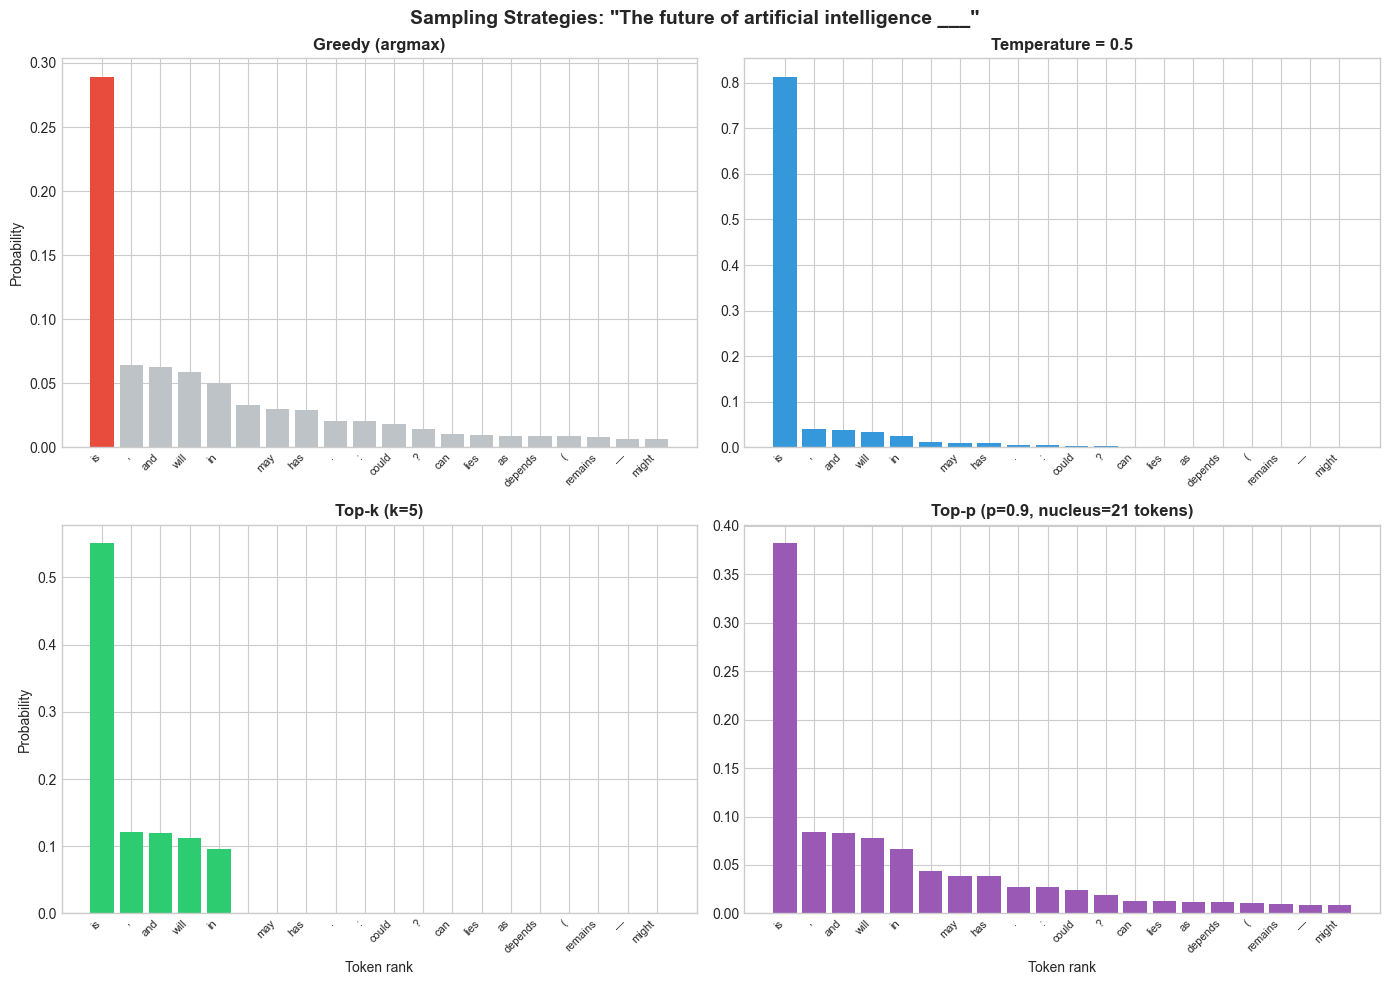

In [6]:
prompt = "The future of artificial intelligence"
logits, probs = get_next_token_probs(prompt)

# Get top 20 tokens for visualization
n_show = 20
sorted_probs, sorted_indices = torch.sort(probs, descending=True)
top_tokens = [tokenizer.decode([idx]).strip() for idx in sorted_indices[:n_show]]
top_probs = sorted_probs[:n_show].numpy()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Greedy
ax = axes[0, 0]
colors = ["#e74c3c" if i == 0 else "#bdc3c7" for i in range(n_show)]
ax.bar(range(n_show), top_probs, color=colors)
ax.set_title("Greedy (argmax)", fontsize=12, fontweight="bold")
ax.set_ylabel("Probability")
ax.set_xticks(range(n_show))
ax.set_xticklabels(top_tokens, rotation=45, ha="right", fontsize=8)

# 2. Temperature sampling (T=0.5)
ax = axes[0, 1]
temp_probs = F.softmax(logits / 0.5, dim=0)
temp_sorted = temp_probs[sorted_indices[:n_show]].numpy()
ax.bar(range(n_show), temp_sorted, color="#3498db")
ax.set_title("Temperature = 0.5", fontsize=12, fontweight="bold")
ax.set_xticks(range(n_show))
ax.set_xticklabels(top_tokens, rotation=45, ha="right", fontsize=8)

# 3. Top-k (k=5)
ax = axes[1, 0]
k = 5
colors = ["#2ecc71" if i < k else "#bdc3c7" for i in range(n_show)]
display_probs = top_probs.copy()
# Re-normalize top-k
topk_renorm = display_probs[:k] / display_probs[:k].sum()
display_probs_k = np.zeros(n_show)
display_probs_k[:k] = topk_renorm
ax.bar(range(n_show), display_probs_k, color=colors)
ax.set_title(f"Top-k (k={k})", fontsize=12, fontweight="bold")
ax.set_ylabel("Probability")
ax.set_xlabel("Token rank")
ax.set_xticks(range(n_show))
ax.set_xticklabels(top_tokens, rotation=45, ha="right", fontsize=8)

# 4. Top-p (p=0.9)
ax = axes[1, 1]
cumsum = np.cumsum(top_probs)
p_threshold = 0.9
nucleus_size = np.searchsorted(cumsum, p_threshold) + 1
colors = ["#9b59b6" if i < nucleus_size else "#bdc3c7" for i in range(n_show)]
display_probs_p = np.zeros(n_show)
nucleus_probs = top_probs[:nucleus_size] / top_probs[:nucleus_size].sum()
display_probs_p[:nucleus_size] = nucleus_probs
ax.bar(range(n_show), display_probs_p, color=colors)
ax.set_title(f"Top-p (p={p_threshold}, nucleus={nucleus_size} tokens)", fontsize=12, fontweight="bold")
ax.set_xlabel("Token rank")
ax.set_xticks(range(n_show))
ax.set_xticklabels(top_tokens, rotation=45, ha="right", fontsize=8)

fig.suptitle(f'Sampling Strategies: "{prompt} ___"', fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Combining Strategies: Temperature + Top-p

In practice, these strategies are **combined**. A common recipe:

1. Apply **temperature** to logits (reshape the distribution)
2. Apply **top-p** filtering (cut the tail)
3. Sample from the filtered distribution

This is what most LLM APIs do behind the scenes.

In [7]:
def sample_with_strategy(logits, temperature=1.0, top_k=None, top_p=None):
    """Combined sampling: temperature → top-k → top-p → sample."""
    # Step 1: Temperature
    scaled_logits = logits / temperature
    
    # Step 2: Top-k filter
    if top_k is not None:
        top_k_values, _ = torch.topk(scaled_logits, top_k)
        threshold = top_k_values[-1]
        scaled_logits[scaled_logits < threshold] = float("-inf")
    
    # Step 3: Top-p filter
    if top_p is not None:
        sorted_logits, sorted_indices = torch.sort(scaled_logits, descending=True)
        sorted_probs = F.softmax(sorted_logits, dim=0)
        cumulative_probs = torch.cumsum(sorted_probs, dim=0)
        
        # Remove tokens with cumulative prob above threshold
        cutoff_mask = (cumulative_probs - sorted_probs) >= top_p
        sorted_logits[cutoff_mask] = float("-inf")
        
        # Unsort
        scaled_logits = sorted_logits.scatter(0, sorted_indices, sorted_logits)
    
    # Step 4: Sample
    probs = F.softmax(scaled_logits, dim=0)
    return torch.multinomial(probs, 1)

# Generate 10 tokens with different strategy combos
prompt = "The best thing about learning to code is"
print(f'Prompt: "{prompt}"\n')

strategies = [
    {"temperature": 0.3, "top_p": None, "top_k": None},
    {"temperature": 0.7, "top_p": 0.9, "top_k": None},
    {"temperature": 1.0, "top_p": 0.95, "top_k": 50},
    {"temperature": 1.5, "top_p": None, "top_k": None},
]

torch.manual_seed(42)
for params in strategies:
    label = f"T={params['temperature']}"
    if params["top_p"]:
        label += f", top_p={params['top_p']}"
    if params["top_k"]:
        label += f", top_k={params['top_k']}"
    
    # Generate a short continuation
    input_ids = tokenizer.encode(prompt, return_tensors="pt")
    generated = input_ids[0].tolist()
    
    for _ in range(20):
        with torch.no_grad():
            out_logits = model(torch.tensor([generated])).logits[0, -1, :]
        next_id = sample_with_strategy(out_logits, **params).item()
        generated.append(next_id)
    
    continuation = tokenizer.decode(generated[input_ids.shape[1]:])
    print(f"  [{label}]")
    print(f"    ...{continuation.strip()}")
    print()

Prompt: "The best thing about learning to code is"

  [T=0.3]
    ...that you can learn it quickly and easily. If you're not familiar with programming, then you can

  [T=0.7, top_p=0.9]
    ...that it gives you the tools to solve problems. In fact, you can learn to code and develop

  [T=1.0, top_p=0.95, top_k=50]
    ...that you learn what to code. That's true of many different things. How can you know what

  [T=1.5]
    ...doing makeup unit tests upfront; by law enforcement or help fight crime, screw management confidence is simple.



## Key Takeaways

| Strategy | Controls | Adaptive? | Best For |
|---|---|---|---|
| **Greedy** | Nothing — always picks argmax | No | Factual, deterministic tasks |
| **Temperature** | Sharpness of distribution | No | General creativity control |
| **Top-k** | Max number of candidates | No | Simple diversity control |
| **Top-p (nucleus)** | Probability mass threshold | Yes | Context-adaptive diversity |
| **Combined** | Multiple knobs | Yes | Production LLM APIs |

**In practice:** Most APIs use temperature + top-p together. OpenAI defaults to `T=1.0, top_p=1.0`. Anthropic uses `T=1.0` by default.

**Next up:** How these single-token predictions chain together into full text generation.